In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

import spatialdata as sd
from spatialdata_io import xenium

import scanpy as sc
import squidpy as sq

warnings.filterwarnings("ignore")

xenium_path = "./Xenium_V1_Human_Ovarian_Cancer_Addon_FFPE_outs"
zarr_path   = "./Xenium_V1_Human_Ovarian_Cancer_Addon_FFPE_outs.zarr"
h5ad_path   = "./adata_processed.h5ad"

start_time = time.time()
last_time  = [start_time]

def step(name):
    now = time.time()
    print(f"[{time.strftime('%Y-%m-%d %H:%M:%S')}] {name} | "
          f"step: {now - last_time[0]:.2f}s | total: {now - start_time:.2f}s")
    last_time[0] = now


def spatial_clusters(adata, key, *, size=1.5, alpha=0.8, palette=None):
    n = adata.obs[key].nunique()

    if isinstance(palette, dict):
        if hasattr(adata.obs[key], "cat"):
            categories = adata.obs[key].cat.categories
        else:
            categories = sorted(adata.obs[key].dropna().unique())
        colors  = [palette.get(cat, "#7f7f7f") for cat in categories]
        palette = ListedColormap(colors)
    elif palette is None:
        palette = "tab20" if n > 10 else "tab10"

    print(f"[spatial] {key}: {n} clusters -> "
          f"{adata.obs[key].value_counts().sort_index().to_dict()}")

    return sq.pl.spatial_scatter(
        adata, shape=None, color=key, size=size, alpha=alpha,
        palette=palette, frameon=False, wspace=0.4,
    )

step("setup done")


c:\ProgramData\spyder-6\envs\xeniumenv\lib\site-packages\dask\dataframe\__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
c:\ProgramData\spyder-6\envs\xeniumenv\lib\site-packages\xarray_schema\__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


[2026-11-04 23:54:51] setup done | step: 0.00s | total: 0.00s


c:\ProgramData\spyder-6\envs\xeniumenv\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
if not os.path.exists(zarr_path):
    sdata = xenium(xenium_path)
    step("xenium loaded")
    sdata.write(zarr_path, overwrite=True)
    step("zarr written")
else:
    step("zarr already exists, skipping xenium conversion")

[2026-11-04 23:54:51] zarr already exists, skipping xenium conversion | step: 0.01s | total: 0.01s


In [3]:
sdata = sd.read_zarr(zarr_path)
step("zarr read")

version mismatch: detected: RasterFormatV02, requested: FormatV04


[2026-11-04 23:54:55] zarr read | step: 3.26s | total: 3.27s


In [4]:
adata = sdata.tables["table"]

sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)
step("qc metrics computed")

cprobes = adata.obs["control_probe_counts"].sum()  / adata.obs["total_counts"].sum() * 100
cwords  = adata.obs["control_codeword_counts"].sum() / adata.obs["total_counts"].sum() * 100
print(f"Negative DNA probe count % : {cprobes}")
print(f"Negative decoding count % : {cwords}")
step("control probes/codewords printed")

[2026-11-04 23:54:55] qc metrics computed | step: 0.47s | total: 3.74s
Negative DNA probe count % : 0.005412905963199077
Negative decoding count % : 0.002127177080274725
[2026-11-04 23:54:55] control probes/codewords printed | step: 0.00s | total: 3.74s


[2026-11-04 23:54:56] qc plots rendered | step: 1.13s | total: 4.87s


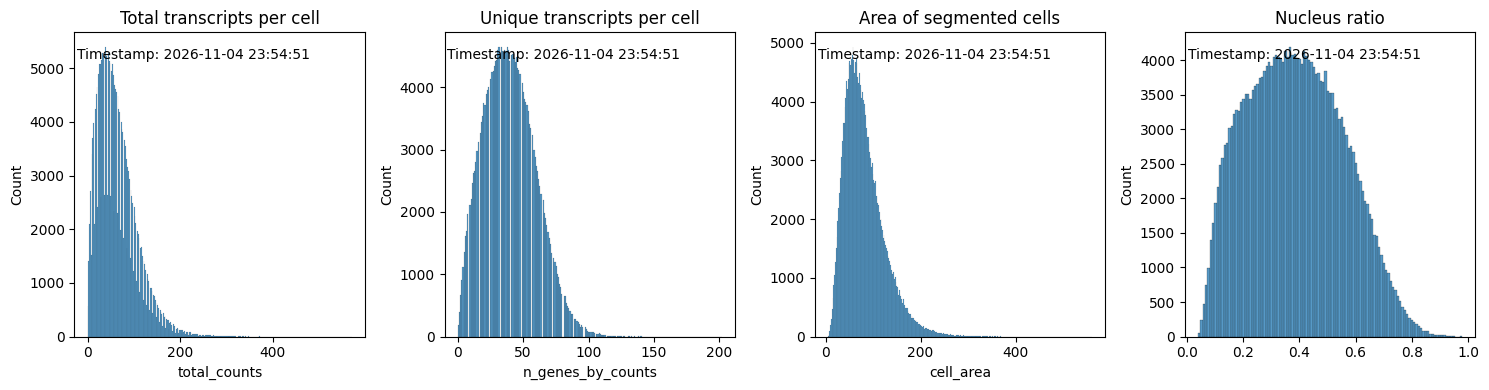

In [5]:
fig, axs = plt.subplots(1, 4, figsize=(15, 4))

axs[0].set_title("Total transcripts per cell")
sns.histplot(adata.obs["total_counts"], kde=False, ax=axs[0])

axs[1].set_title("Unique transcripts per cell")
sns.histplot(adata.obs["n_genes_by_counts"], kde=False, ax=axs[1])

axs[2].set_title("Area of segmented cells")
sns.histplot(adata.obs["cell_area"], kde=False, ax=axs[2])

axs[3].set_title("Nucleus ratio")
sns.histplot(adata.obs["nucleus_area"] / adata.obs["cell_area"], kde=False, ax=axs[3])

for ax in axs:
    ax.text(
        0.01, 0.95,
        f"Timestamp: {time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(start_time))}",
        transform=ax.transAxes, fontsize=10, verticalalignment="top",
    )

plt.tight_layout()
step("qc plots rendered")

In [6]:
print(f"Before filtering: {adata.n_obs} cells x {adata.n_vars} genes")
sc.pp.filter_cells(adata, min_counts=10)
sc.pp.filter_genes(adata, min_cells=5)
print(f"After filtering:  {adata.n_obs} cells x {adata.n_vars} genes")
step("cells and genes filtered")

Before filtering: 247636 cells x 480 genes
After filtering:  237652 cells x 480 genes
[2026-11-04 23:54:57] cells and genes filtered | step: 0.91s | total: 5.78s


In [7]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
step("normalized and log1p")

[2026-11-04 23:54:57] normalized and log1p | step: 0.17s | total: 5.94s


In [8]:
sc.pp.pca(adata)
step("pca done")

sc.pp.neighbors(adata)
step("neighbors done")

sc.tl.umap(adata)
step("umap done")

sc.tl.leiden(
    adata,
    resolution=1.0,
    key_added="leiden",
    flavor="leidenalg",
    n_iterations=2,
)
print(f"Leiden found {adata.obs['leiden'].nunique()} clusters")
step("leiden done")

[2026-11-04 23:55:00] pca done | step: 2.62s | total: 8.56s
[2026-11-04 23:55:55] neighbors done | step: 55.40s | total: 63.97s
[2026-11-04 23:57:54] umap done | step: 118.53s | total: 182.50s
Leiden found 6 clusters
[2026-11-04 23:58:18] leiden done | step: 24.59s | total: 207.09s


In [9]:
adata.write(h5ad_path)
step("adata checkpoint saved")

[2026-11-04 23:58:19] adata checkpoint saved | step: 0.57s | total: 207.66s


[2026-11-04 23:58:19] umap plots rendered | step: 0.46s | total: 208.12s


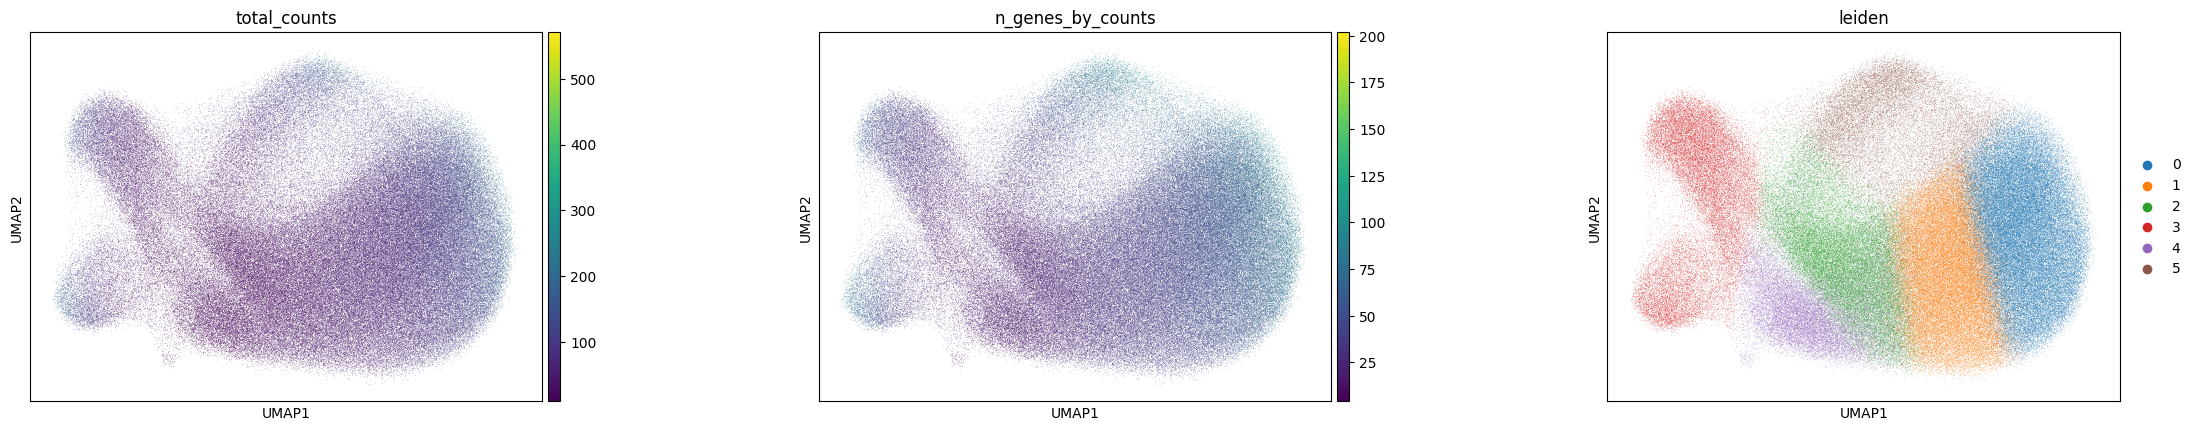

In [10]:
sc.pl.umap(
    adata,
    color=["total_counts", "n_genes_by_counts", "leiden"],
    wspace=0.4,
    show=False,
)
step("umap plots rendered")

[spatial] leiden: 6 clusters -> {'0': 67432, '1': 52078, '2': 40543, '3': 30877, '4': 24279, '5': 22443}
[2026-11-04 23:58:25] spatial plots rendered | step: 5.88s | total: 214.00s


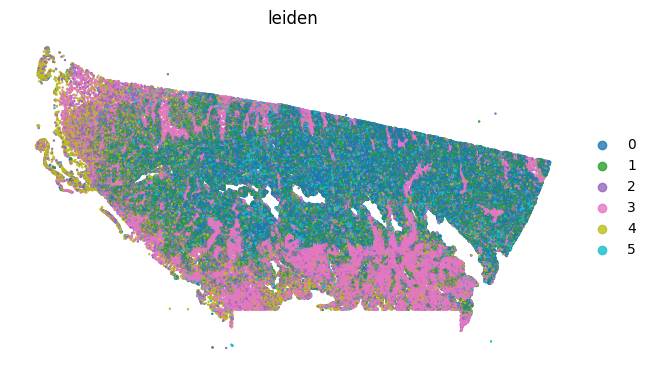

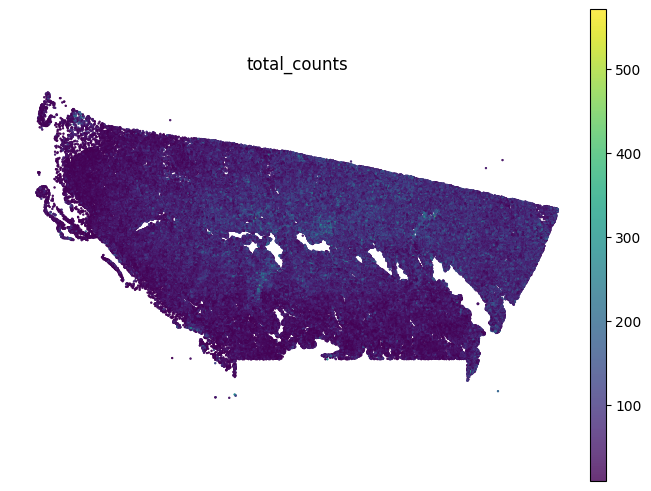

In [11]:
spatial_clusters(adata, "leiden")

sq.pl.spatial_scatter(
    adata, shape=None, color="total_counts",
    size=1.5, alpha=0.8, frameon=False,
)
step("spatial plots rendered")

In [12]:
from napari_spatialdata import Interactive

interactive = Interactive(sdata)
interactive.add_element("morphology_focus", "global")
interactive.add_element("cell_labels", "global")
interactive.run()

2026-11-04 23:58:47.786 | WARNING  | napari_spatialdata._viewer:__init__:57 - Due to Shift-L being used as shortcut in napari, it is being deprecated and might not link a new layer to an existing SpatialData object in the viewer. Please use ⌘-L on MacOS or else Ctrl-L.


In [13]:
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden",
    method="wilcoxon",
    key_added="rank_leiden",
    pts=True,
)
step("rank_genes_groups (wilcoxon) done")

rg = sc.get.rank_genes_groups_df(adata, group=None, key="rank_leiden")
print(f"rank_genes_groups rows: {len(rg)} (groups x genes)")
print(rg.head())
print(f"leiden groups: {sorted(adata.obs['leiden'].unique(), key=int)}")
step("rank results summarized")

[2026-11-04 23:58:56] rank_genes_groups (wilcoxon) done | step: 31.05s | total: 245.05s
rank_genes_groups rows: 2880 (groups x genes)
  group  names      scores  logfoldchanges  pvals  pvals_adj  pct_nz_group  \
0     0   KRAS  141.384125        3.364738    0.0        0.0      0.931694   
1     0    ID4  140.786331        3.417065    0.0        0.0      0.816363   
2     0  ERBB3  136.003738        3.374651    0.0        0.0      0.770361   
3     0  EPCAM  131.591812        3.275871    0.0        0.0      0.941689   
4     0  PRDX4  126.589394        3.107283    0.0        0.0      0.634432   

   pct_nz_reference  
0          0.518776  
1          0.381630  
2          0.327629  
3          0.540360  
4          0.237487  
leiden groups: ['0', '1', '2', '3', '4', '5']
[2026-11-04 23:58:56] rank results summarized | step: 0.03s | total: 245.08s


2026-11-04 23:58:57.193 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-11-04 23:58:57.194 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-11-04 23:58:57.470 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.
2026-11-04 23:58:57.477 | DEBUG    | napari_spatialdata._view:_on_layer_update:569 - Updating layer.


In [14]:
n_top    = 3
min_lfc  = 0.25
max_padj = 0.05

sig = rg[(rg["pvals_adj"] < max_padj) & (rg["logfoldchanges"] > min_lfc)].copy()
print(f"Significant genes: {len(sig)} / {len(rg)}")

top = (
    sig.sort_values("scores", ascending=False)
       .groupby("group", observed=True)
       .head(n_top)
)

marker_genes = top["names"].drop_duplicates().tolist()
print(f"Selected {len(marker_genes)} unique marker genes across {top['group'].nunique()} clusters")
print("Markers per cluster:")
print(top.groupby("group", observed=True)["names"].apply(list).to_string())
step("marker_genes selected")

Significant genes: 535 / 2880
Selected 13 unique marker genes across 6 clusters
Markers per cluster:
group
0      [KRAS, ID4, ERBB3]
1      [EPCAM, KRAS, C1R]
2                  [ACTB]
3    [SPARC, IGFBP7, FN1]
4                  [IGKC]
5      [CD74, APOE, CTSD]
[2026-11-04 23:58:57] marker_genes selected | step: 0.64s | total: 245.72s


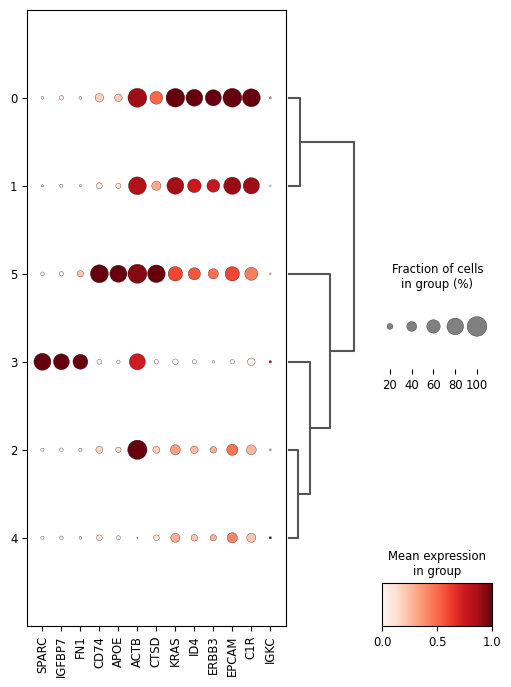

[2026-11-04 23:58:57] dotplot rendered | step: 0.46s | total: 246.18s


In [15]:
dp = sc.pl.dotplot(
    adata,
    var_names=marker_genes,
    groupby="leiden",
    standard_scale="var",
    cmap="Reds",
    dendrogram=True,
    figsize=(max(6, 0.35 * len(marker_genes)), 8),
    return_fig=True,
    show=False,
)
dp.show()
step("dotplot rendered")

In [16]:
leiden   = adata.obs["leiden"].astype(str)
clusters = sorted(leiden.unique(), key=lambda x: int(x) if x.isdigit() else x)

X = adata.X.tocsr() if sp.issparse(adata.X) else np.asarray(adata.X)
gene_idx = adata.var_names.get_indexer(marker_genes)
assert (gene_idx >= 0).all(), f"missing genes: {[g for g, i in zip(marker_genes, gene_idx) if i < 0]}"

mean = np.zeros((len(clusters), len(marker_genes)))
frac = np.zeros_like(mean)
for i, c in enumerate(clusters):
    m = (leiden == c).values
    sub = X[m][:, gene_idx]
    mean[i] = np.asarray(sub.mean(axis=0)).ravel()
    frac[i] = np.asarray((sub > 0).sum(axis=0)).ravel() / m.sum()

frac_df = pd.DataFrame(frac, index=clusters, columns=marker_genes)
mean_df = pd.DataFrame(mean, index=clusters, columns=marker_genes)

print(f"cluster sizes: {leiden.value_counts().sort_index().to_dict()}")
print(f"frac_df  shape={frac_df.shape}  range=[{frac.min():.3f}, {frac.max():.3f}]")
print(f"mean_df  shape={mean_df.shape}  range=[{mean.min():.3f}, {mean.max():.3f}]")

rg_wide = rg.pivot(index="group", columns="names", values="pct_nz_group")
rows = [r for r in frac_df.index if r in rg_wide.index]
cols = [c for c in frac_df.columns if c in rg_wide.columns]
delta = (frac_df.loc[rows, cols] - rg_wide.loc[rows, cols]).abs()
print(f"max |frac_df - pct_nz_group| = {delta.values.max():.2e}")

per_gene = pd.DataFrame({
    "max_frac": frac_df.max(axis=0),
    "argmax":   frac_df.idxmax(axis=0),
    "max_mean": mean_df.max(axis=0),
}).sort_values("max_frac", ascending=False)
print("\nPer-marker summary (top 15 by max fraction):")
print(per_gene.head(15).round(3).to_string())

per_cluster = pd.DataFrame({
    "n_markers_frac>0.5": (frac_df > 0.5).sum(axis=1),
    "n_markers_frac>0.2": (frac_df > 0.2).sum(axis=1),
    "mean_frac":          frac_df.mean(axis=1),
})
print("\nPer-cluster marker coverage:")
print(per_cluster.round(3).to_string())

print("\nFull fraction matrix (fraction of cells expressing):")
print(frac_df.round(2).to_string())
step("dotplot numbers inspected")

cluster sizes: {'0': 67432, '1': 52078, '2': 40543, '3': 30877, '4': 24279, '5': 22443}
frac_df  shape=(6, 13)  range=[0.024, 0.977]
mean_df  shape=(6, 13)  range=[0.140, 6.215]
max |frac_df - pct_nz_group| = 0.00e+00

Per-marker summary (top 15 by max fraction):
        max_frac argmax  max_mean
ACTB       0.977      2     6.215
EPCAM      0.942      0     5.400
KRAS       0.932      0     5.278
C1R        0.887      0     5.002
CD74       0.886      5     4.995
CTSD       0.865      5     4.812
APOE       0.831      5     4.681
SPARC      0.826      3     5.139
ID4        0.816      0     4.415
ERBB3      0.770      0     4.002
IGFBP7     0.755      3     4.714
FN1        0.691      3     4.302
IGKC       0.059      3     0.359

Per-cluster marker coverage:
   n_markers_frac>0.5  n_markers_frac>0.2  mean_frac
0                   7                   9      0.524
1                   6                   7      0.420
2                   1                   8      0.291
3                 

In [17]:
profiles = np.vstack([
    np.asarray(X[(leiden == c).values].mean(axis=0)).ravel() for c in clusters
])
corr = np.corrcoef(profiles)
corr_df = pd.DataFrame(corr, index=clusters, columns=clusters)

off = corr.copy()
np.fill_diagonal(off, -np.inf)
flat = np.argsort(off.ravel())[::-1]

seen, pairs = set(), []
for k in flat:
    i, j = np.unravel_index(k, corr.shape)
    if i < j and (i, j) not in seen:
        seen.add((i, j))
        pairs.append((clusters[i], clusters[j], corr[i, j]))
    if len(pairs) == 5:
        break

print("Top 5 most similar cluster pairs (Pearson r on mean log-norm profile):")
for a, b, r in pairs:
    print(f"  cluster {a}  vs  cluster {b} :  r = {r:.4f}")

print("\nFull correlation matrix:")
print(corr_df.round(3).to_string())
step("cluster similarity computed")

Top 5 most similar cluster pairs (Pearson r on mean log-norm profile):
  cluster 0  vs  cluster 1 :  r = 0.9884
  cluster 1  vs  cluster 4 :  r = 0.9433
  cluster 1  vs  cluster 2 :  r = 0.9424
  cluster 0  vs  cluster 4 :  r = 0.9399
  cluster 0  vs  cluster 2 :  r = 0.9202

Full correlation matrix:
       0      1      2      3      4      5
0  1.000  0.988  0.920  0.439  0.940  0.806
1  0.988  1.000  0.942  0.442  0.943  0.801
2  0.920  0.942  1.000  0.539  0.851  0.857
3  0.439  0.442  0.539  1.000  0.469  0.444
4  0.940  0.943  0.851  0.469  1.000  0.804
5  0.806  0.801  0.857  0.444  0.804  1.000
[2026-11-04 23:58:58] cluster similarity computed | step: 0.13s | total: 246.64s


In [18]:
qc = adata.obs.groupby("leiden", observed=True).agg(
    n_cells          = ("leiden", "size"),
    total_counts_med = ("total_counts", "median"),
    total_counts_p10 = ("total_counts", lambda x: np.percentile(x, 10)),
    n_genes_med      = ("n_genes_by_counts", "median"),
    cell_area_med    = ("cell_area", "median"),
    nucleus_ratio    = ("nucleus_area", lambda x: np.median(x / adata.obs.loc[x.index, "cell_area"])),
).round(2)
print(qc.to_string())
step("per-cluster QC inspected")

        n_cells  total_counts_med  total_counts_p10  n_genes_med  cell_area_med  nucleus_ratio
leiden                                                                                        
0         67432              98.0              67.0         58.0          85.93           0.44
1         52078              56.0              39.0         39.0          59.34           0.45
2         40543              30.0              16.0         24.0          56.22           0.35
3         30877              47.0              20.0         30.0         117.27           0.20
4         24279              22.0              12.0         19.0          53.56           0.35
5         22443              83.0              48.0         55.0          81.01           0.37
[2026-11-04 23:58:58] per-cluster QC inspected | step: 0.12s | total: 246.75s


merged cluster sizes:
leiden_m
0+1    119510
2       40543
3       30877
4       24279
5       22443
[2026-11-04 23:58:58] merged dotplot rendered | step: 0.39s | total: 247.14s


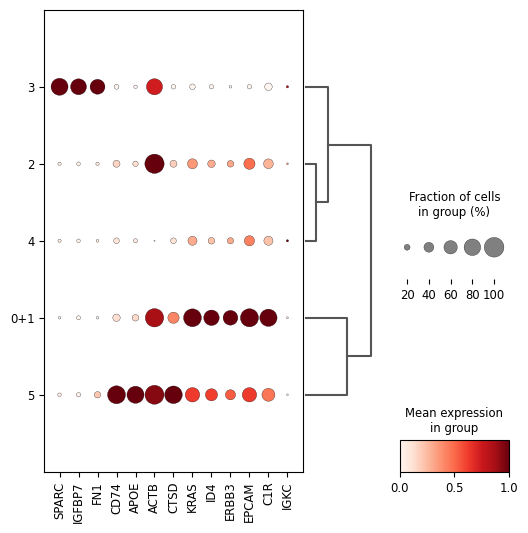

In [19]:
merge_map = {"0": "0+1", "1": "0+1"}
adata.obs["leiden_m"] = adata.obs["leiden"].astype(str).replace(merge_map)

print("merged cluster sizes:")
print(adata.obs["leiden_m"].value_counts().sort_index().to_string())

sc.pl.dotplot(
    adata, var_names=marker_genes, groupby="leiden_m",
    standard_scale="var", cmap="Reds", dendrogram=True,
    figsize=(max(6, 0.35 * len(marker_genes)), 6), show=False,
)
step("merged dotplot rendered")

significant & meaningful: 253 / 2880
tightened markers: ['SPARC', 'IGFBP7', 'CD74', 'APOE', 'ACTB', 'KRAS', 'ID4', 'EPCAM']
group
0        [KRAS, ID4]
1      [EPCAM, KRAS]
2             [ACTB]
3    [SPARC, IGFBP7]
5       [CD74, APOE]
[2026-11-04 23:58:59] tightened markers plotted | step: 0.42s | total: 247.56s


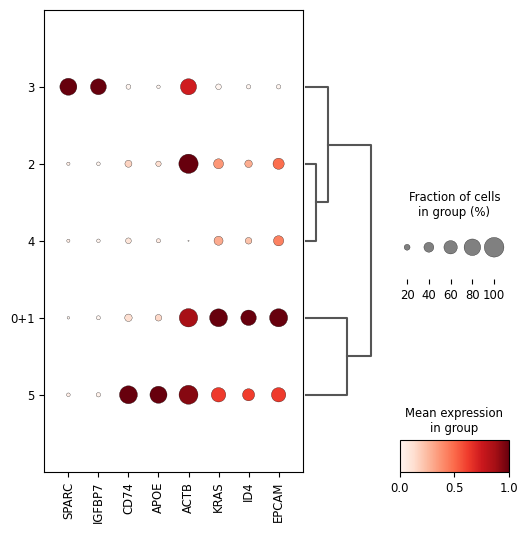

In [20]:
n_top    = 2
min_lfc  = 1.0
min_frac = 0.10

sig = rg[
    (rg["pvals_adj"] < 0.05)
    & (rg["logfoldchanges"] > min_lfc)
    & (rg["pct_nz_group"] > min_frac)
].copy()
print(f"significant & meaningful: {len(sig)} / {len(rg)}")

top = sig.sort_values("scores", ascending=False).groupby("group", observed=True).head(n_top)
marker_genes2 = top["names"].drop_duplicates().tolist()
print("tightened markers:", marker_genes2)
print(top.groupby("group", observed=True)["names"].apply(list).to_string())

sc.pl.dotplot(
    adata, var_names=marker_genes2, groupby="leiden_m",
    standard_scale="var", cmap="Reds", dendrogram=True,
    figsize=(max(6, 0.35 * len(marker_genes2)), 6), show=False,
)
step("tightened markers plotted")

[spatial] leiden: 6 clusters -> {'0': 67432, '1': 52078, '2': 40543, '3': 30877, '4': 24279, '5': 22443}
[spatial] leiden_m: 5 clusters -> {'0+1': 119510, '2': 40543, '3': 30877, '4': 24279, '5': 22443}
[2026-11-04 23:59:00] spatial plots rendered (leiden + leiden_m + total_counts) | step: 0.98s | total: 248.54s


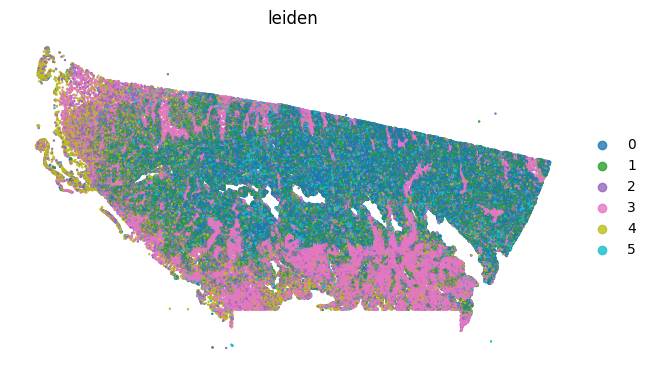

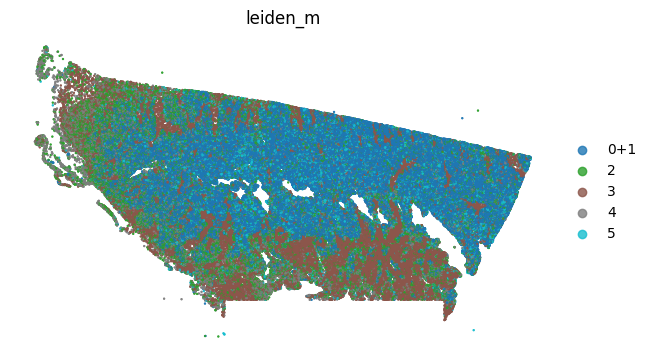

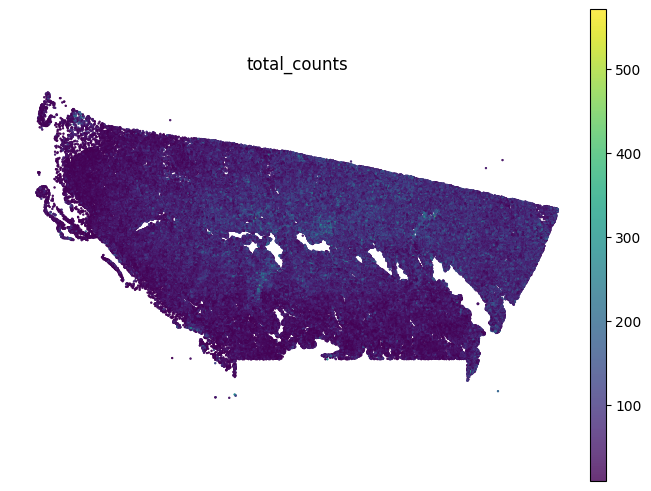

In [21]:
spatial_clusters(adata, "leiden")
spatial_clusters(adata, "leiden_m")

sq.pl.spatial_scatter(
    adata, shape=None, color="total_counts",
    size=1.5, alpha=0.8, frameon=False,
)
step("spatial plots rendered (leiden + leiden_m + total_counts)")

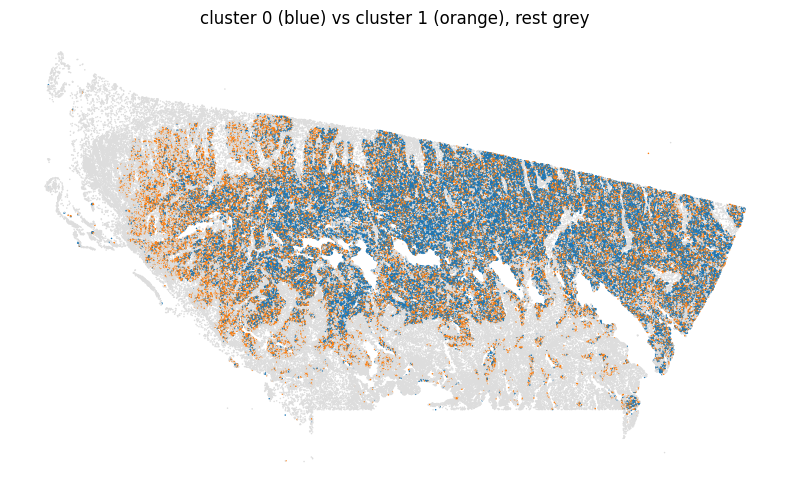

[2026-11-04 23:59:26] 0 vs 1 spatial overlay rendered | step: 26.10s | total: 274.64s


In [22]:
lab = adata.obs["leiden"].astype(str).values
colors = np.select(
    [lab == "0", lab == "1"],
    ["#1f77b4", "#ff7f0e"],
    default="#dddddd",
)
xy = np.asarray(adata.obsm["spatial"])[:, :2]

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(xy[:, 0], xy[:, 1], c=colors, s=1.2, linewidths=0)
ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title("cluster 0 (blue) vs cluster 1 (orange), rest grey")
plt.tight_layout()
plt.show()
step("0 vs 1 spatial overlay rendered")

In [23]:
adata_scaled = adata.copy()

sc.pp.scale(adata_scaled, max_value=10)
sc.pp.pca(adata_scaled, n_comps=30)
sc.pp.neighbors(adata_scaled, n_neighbors=15)
sc.tl.leiden(
    adata_scaled, resolution=1.0, key_added="leiden_scaled",
    flavor="leidenalg", n_iterations=2,
)

old = adata.obs["leiden"].astype(str)
new = adata_scaled.obs["leiden_scaled"].astype(str)
mask = old.isin(["0", "1"])

ct = pd.crosstab(old[mask], new[mask])
print("Cross-tab of old (0/1) vs new clusters for those cells:")
print(ct.to_string())

max_col = ct.sum(axis=0).idxmax()
frac    = ct.loc[:, max_col].sum() / ct.values.sum()
print(f"\n{frac:.1%} of old 0+1 cells land in new cluster {max_col}")
step("scaled PCA/leiden hypothesis test done")

Cross-tab of old (0/1) vs new clusters for those cells:
leiden_scaled      0     1    10    11    12    13  14      2     3      4    5    6     7     8     9
leiden                                                                                                
0              16662    12  2468   429  2380  4415   4  23759  2422   4907   45  519  4863   630  3917
1              14899  1580  2056  1128  1985   537  17   2673  1400  13022  142  733  3283  6175  2448

26.4% of old 0+1 cells land in new cluster 0
[2026-11-05 00:00:24] scaled PCA/leiden hypothesis test done | step: 57.95s | total: 332.58s


In [24]:
annotation_map = {
    "0+1": "Epithelial / Tumor",
    "2":   "Epithelial (Low-count)",
    "3":   "Fibroblast / CAF",
    "4":   "Low-content / Artifact",
    "5":   "Macrophage / Myeloid",
}

adata.obs["cell_type"] = adata.obs["leiden_m"].map(annotation_map).astype("category")

print("Cell type counts:")
print(adata.obs["cell_type"].value_counts().to_string())
print(f"Missing labels: {adata.obs['cell_type'].isna().sum()} cells")
step("clusters annotated")

Cell type counts:
cell_type
Epithelial / Tumor        119510
Epithelial (Low-count)     40543
Fibroblast / CAF           30877
Low-content / Artifact     24279
Macrophage / Myeloid       22443
Missing labels: 0 cells
[2026-11-05 00:00:24] clusters annotated | step: 0.02s | total: 332.60s


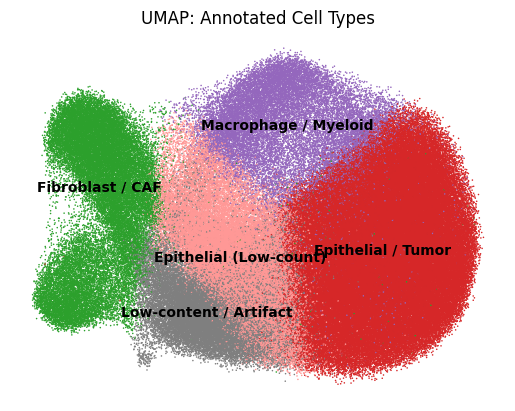

[spatial] cell_type: 5 clusters -> {'Epithelial / Tumor': 119510, 'Epithelial (Low-count)': 40543, 'Fibroblast / CAF': 30877, 'Low-content / Artifact': 24279, 'Macrophage / Myeloid': 22443}
[2026-11-05 00:00:26] annotated UMAP and spatial plots rendered | step: 1.68s | total: 334.29s


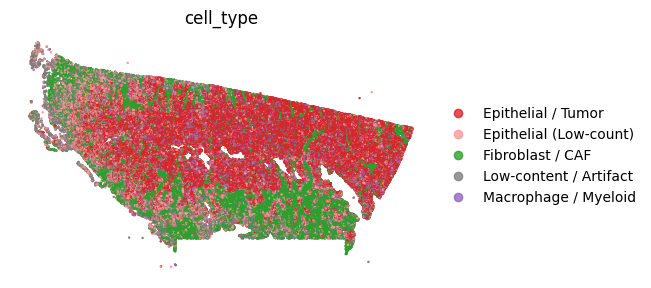

In [25]:
pal = {
    "Epithelial / Tumor":     "#d62728",
    "Epithelial (Low-count)": "#ff9896",
    "Fibroblast / CAF":       "#2ca02c",
    "Macrophage / Myeloid":   "#9467bd",
    "Low-content / Artifact": "#7f7f7f",
}

sc.pl.umap(
    adata, color="cell_type", palette=pal,
    size=5, legend_loc="on data", frameon=False, show=False,
)
plt.title("UMAP: Annotated Cell Types")
plt.show()

spatial_clusters(adata, "cell_type", palette=pal, size=1.5)
step("annotated UMAP and spatial plots rendered")

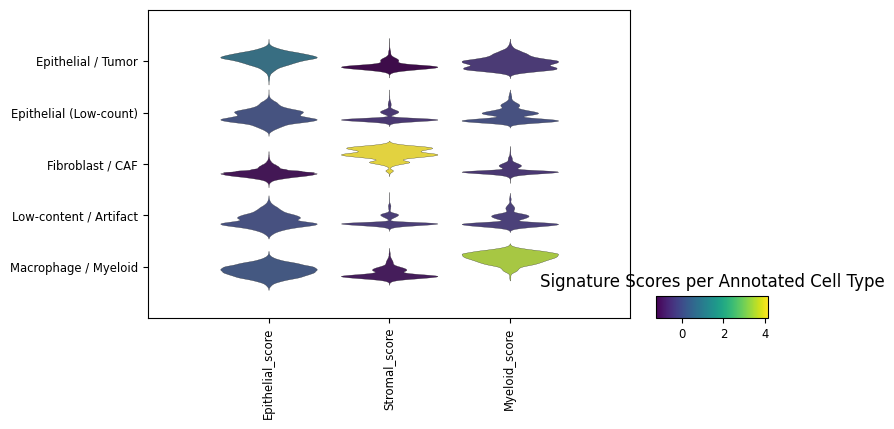

[2026-11-05 00:00:38] gene signature scores validated | step: 12.09s | total: 346.38s


In [26]:
signatures = {
    "Epithelial": ["EPCAM", "KRAS", "ERBB3"],
    "Stromal":    ["SPARC", "FN1", "IGFBP7"],
    "Myeloid":    ["CD74", "APOE", "CTSD"],
}

for name, genes in signatures.items():
    valid = [g for g in genes if g in adata.var_names]
    sc.tl.score_genes(adata, valid, score_name=f"{name}_score")

sc.pl.stacked_violin(
    adata,
    var_names=[f"{n}_score" for n in signatures],
    groupby="cell_type",
    cmap="viridis",
    figsize=(8, 4),
    show=False,
)
plt.title("Signature Scores per Annotated Cell Type")
plt.show()
step("gene signature scores validated")

In [27]:
annotated_h5ad_path = "./adata_annotated.h5ad"
adata.write(annotated_h5ad_path)
print(f"Annotated data saved to {annotated_h5ad_path}")

summary = adata.obs.groupby("cell_type", observed=True).agg(
    n_cells=("cell_type", "size"),
    pct_total=("cell_type", lambda x: len(x) / len(adata) * 100),
    median_counts=("total_counts", "median"),
    median_genes=("n_genes_by_counts", "median"),
).round(2)
print("\nFinal Annotation Summary:")
print(summary.to_string())
step("annotated data exported")

Annotated data saved to ./adata_annotated.h5ad

Final Annotation Summary:
                        n_cells  pct_total  median_counts  median_genes
cell_type                                                              
Epithelial / Tumor       119510      50.29           76.0          49.0
Epithelial (Low-count)    40543      17.06           30.0          24.0
Fibroblast / CAF          30877      12.99           47.0          30.0
Low-content / Artifact    24279      10.22           22.0          19.0
Macrophage / Myeloid      22443       9.44           83.0          55.0
[2026-11-05 00:00:38] annotated data exported | step: 0.60s | total: 346.97s
